In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the CSV file
df = pd.read_csv('VideoGamesSales.csv')
#df=df[df.duplicated()]
df=df.drop_duplicates()
df['Region']=df['Region'].fillna('North')
df['NA_Sales']=df['NA_Sales'].replace('[$]','',regex=True)
df['NA_Sales'] = pd.to_numeric(df['NA_Sales'], errors='coerce')
Average_Sales=df['NA_Sales'].mean()
Average_Sales=int(Average_Sales)
df['NA_Sales']=df['NA_Sales'].fillna(Average_Sales)

df['Country']=df['Country'].replace({'USA':'United States'})
df['Country']=df['Country'].str.title()
df=df.rename(columns={'NA_Sales':'National Sales','Global_Sales':'Global Sales','NA_Profit':'National Profit','Global_Profit':'Global Profit'})

sales_cap = df['National Sales'].quantile(0.95)
df['National Sales'] = np.where(df['National Sales'] > sales_cap, sales_cap, df['National Sales'])
df.head(5)


,Rank,Name,Platform,Year,Month,Genre,Publisher,Country,City,State,Region,National Sales,Global Sales,National Profit,Global Profit
0,1,Wii Sports,Wii,2010,Jan,Sports,Nintendo,United States,Fairfield,California,West,2.07,82.74,12.447,24.822
1,2,Super Mario Bros.,NES,2010,Feb,Platform,Nintendo,United States,Edmonds,Washington,West,2.07,40.24,8.724,12.072
2,3,Mario Kart Wii,Wii,2010,Mar,Racing,Nintendo,United States,Louisville,Kentucky,South,2.07,35.82,4.755,10.746
3,4,Wii Sports Resort,Wii,2010,Apr,Sports,Nintendo,United States,Round Rock,Texas,Central,2.07,33.00,4.725,9.900
4,5,Pokemon Red/Pokemon Blue,GB,2010,May,Role-Playing,Nintendo,United States,Nashville,Tennessee,South,2.07,31.37,3.381,9.411


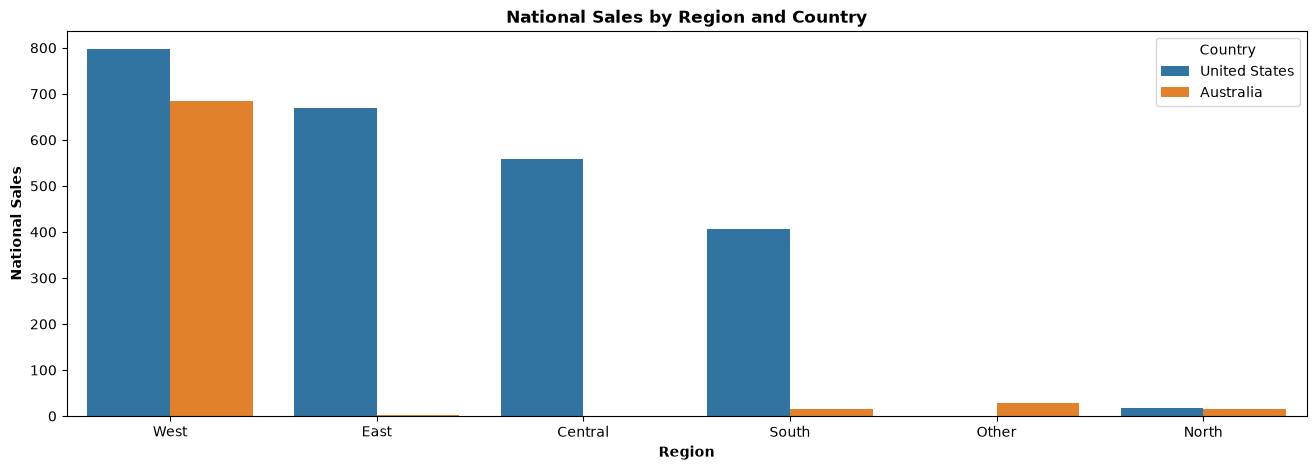

In [2]:
# CREATE A BAR CHART

National_Sales = (
    df.groupby(['Region', 'Country'], as_index=False)['National Sales']
      .sum()
      .rename(columns={'National Sales': 'National_Sales'})
      .sort_values(by='National_Sales', ascending=False)
)

plt.figure(figsize=(16, 5))
sns.barplot(data=National_Sales, x='Region', y='National_Sales', hue='Country')
plt.title('National Sales by Region and Country', fontweight='bold')
plt.xlabel('Region', fontweight='bold')
plt.ylabel('National Sales', fontweight='bold')
plt.show()

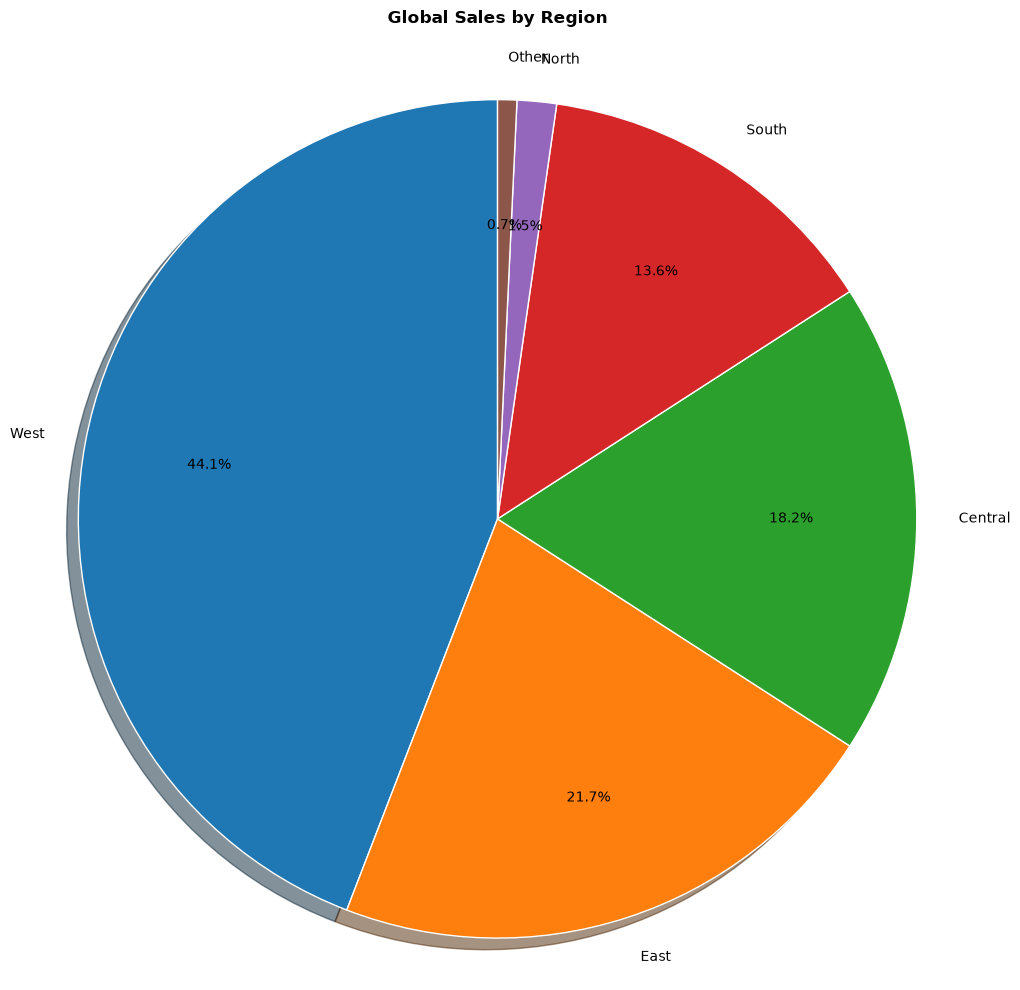

In [3]:
# Pie chart for Global Sales by Region
global_sales_by_region = (
    df.groupby('Region', as_index=False)['Global Sales']
      .sum()
      .rename(columns={'Global Sales': 'Global_Sales'})
      .sort_values('Global_Sales', ascending=False)
)

plt.figure(figsize=(10, 10))
ax = plt.gca()
ax.set_title('Global Sales by Region', fontweight='bold', pad=25)

wedges, texts, autotexts = plt.pie(
    global_sales_by_region['Global_Sales'],
    labels=global_sales_by_region['Region'],
    autopct='%1.1f%%',
    startangle=90,
    shadow=True,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1},
    labeldistance=1.1,
    pctdistance=0.7,
    rotatelabels=False
)

for text in texts + autotexts:
    text.set_fontsize(10)

plt.tight_layout()
plt.axis('equal')
plt.show()